# IML 2026: Introduction to Machine Learning
## LAB 05 — SVM

### Soumik Bhattacharyya, MDE2026005


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import make_blobs, make_moons
from sklearn.model_selection import train_test_split
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score

1. Generate a two-class dataset using `make_blobs()` with 100 samples and two features. Plot it using different colors for the two classes.

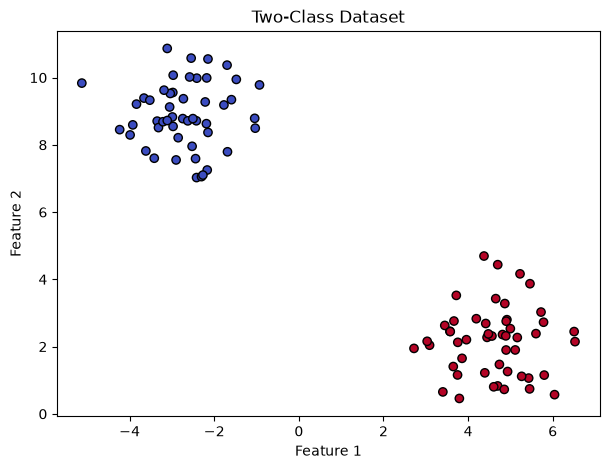

In [2]:
X, y = make_blobs(
    n_samples=100,
    centers=2,
    n_features=2,
    random_state=42
)

plt.figure(figsize=(7, 5))
plt.scatter(X[:, 0], X[:, 1], c=y, cmap="coolwarm", edgecolors="k")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.title("Two-Class Dataset")
plt.show()

**Question 1(c):** What do the two features and two colors represent?

The two features represent the two numerical attributes of each data point, shown on the x-axis and y-axis. The two colors represent the two different classes in the dataset.

2. Split the dataset into 80% training and 20% testing data. Train `SVC(kernel="linear")`, predict the test labels, and calculate classification accuracy.

In [3]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

linear_svm = SVC(kernel="linear")
linear_svm.fit(X_train, y_train)

y_pred = linear_svm.predict(X_test)
linear_test_accuracy = accuracy_score(y_test, y_pred)

print("Test accuracy:", linear_test_accuracy)

Test accuracy: 1.0


3. Plot the dataset with the SVM decision boundary, both margin lines, and highlighted support vectors.

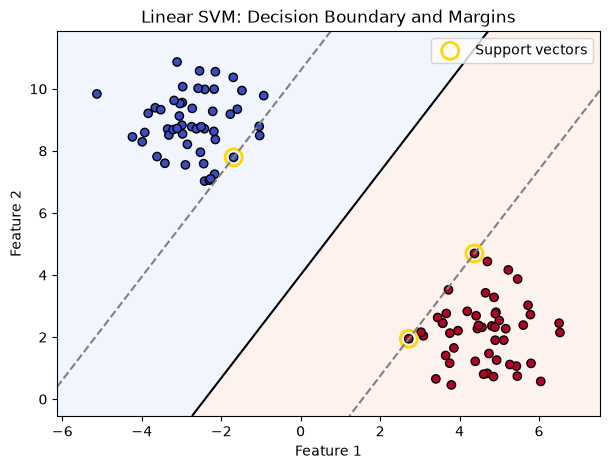

Number of support vectors: 3


In [4]:
def plot_svm_boundary(model, X, y, title):
    x_min, x_max = X[:, 0].min() - 1, X[:, 0].max() + 1
    y_min, y_max = X[:, 1].min() - 1, X[:, 1].max() + 1
    xx, yy = np.meshgrid(
        np.linspace(x_min, x_max, 400),
        np.linspace(y_min, y_max, 400)
    )
    grid = np.c_[xx.ravel(), yy.ravel()]
    scores = model.decision_function(grid).reshape(xx.shape)

    plt.figure(figsize=(7, 5))
    plt.contourf(xx, yy, scores, levels=[-100, 0, 100], alpha=0.12, cmap="coolwarm")
    plt.contour(xx, yy, scores, levels=[-1, 0, 1], colors=["gray", "black", "gray"],
                linestyles=["--", "-", "--"])
    plt.scatter(X[:, 0], X[:, 1], c=y, cmap="coolwarm", edgecolors="k")
    plt.scatter(
        model.support_vectors_[:, 0],
        model.support_vectors_[:, 1],
        s=150,
        facecolors="none",
        edgecolors="gold",
        linewidths=2,
        label="Support vectors"
    )
    plt.xlabel("Feature 1")
    plt.ylabel("Feature 2")
    plt.title(title)
    plt.legend()
    plt.show()

plot_svm_boundary(linear_svm, X, y, "Linear SVM: Decision Boundary and Margins")
print("Number of support vectors:", len(linear_svm.support_vectors_))

**Question 3(c):** What are support vectors? Why are they important for the decision boundary?

Support vectors are the data points closest to the decision boundary. They are important because they determine the position and orientation of the decision boundary and help define the margin.

4. For true label `y = +1`, calculate hinge loss for scores `-1, 0, 0.5, 1, 2`. Plot hinge loss against scores from -2 to 3.

,Model score,Hinge loss
0,-1.0,2.0
1,0.0,1.0
2,0.5,0.5
3,1.0,0.0
4,2.0,0.0


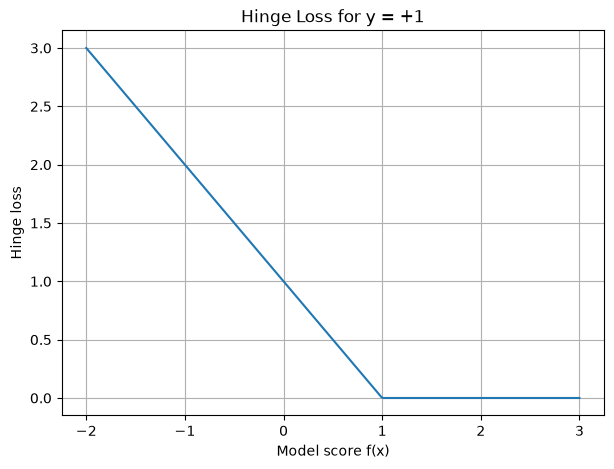

In [5]:
scores_to_check = np.array([-1, 0, 0.5, 1, 2])
true_label = 1
hinge_losses = np.maximum(0, 1 - true_label * scores_to_check)

hinge_results = pd.DataFrame({
    "Model score": scores_to_check,
    "Hinge loss": hinge_losses
})
display(hinge_results)

score_values = np.linspace(-2, 3, 300)
loss_values = np.maximum(0, 1 - score_values)

plt.figure(figsize=(7, 5))
plt.plot(score_values, loss_values)
plt.xlabel("Model score f(x)")
plt.ylabel("Hinge loss")
plt.title("Hinge Loss for y = +1")
plt.grid(True)
plt.show()

**Question 4(c):** At what value of \(yf(x)\) does hinge loss become zero?

Hinge loss becomes zero when \(yf(x) \geq 1\), meaning the sample is correctly classified with a margin of at least 1.

5. Train linear SVM models with `C = 0.1, 1, 100`. Plot each decision boundary and margins, then compare margin widths and support-vector counts.

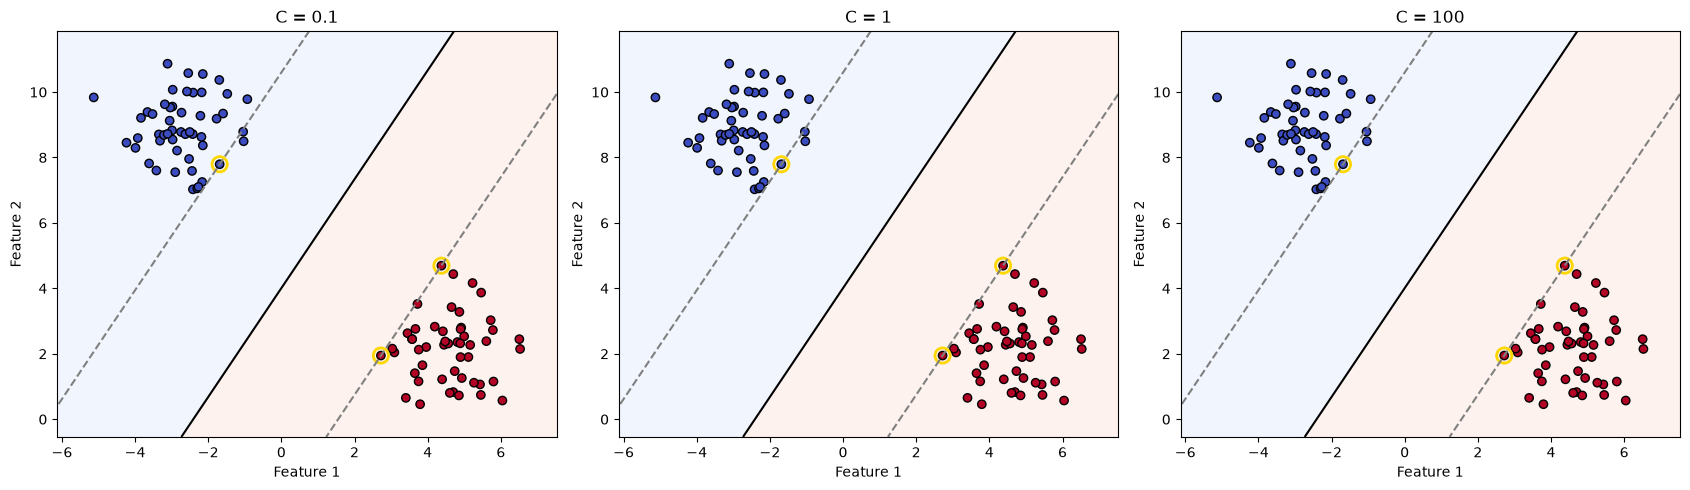

,C,Number of support vectors,Training accuracy,Testing accuracy
0,0.1,3,1.0,1.0
1,1.0,3,1.0,1.0
2,100.0,3,1.0,1.0


In [6]:
C_values = [0.1, 1, 100]
C_models = {}

fig, axes = plt.subplots(1, 3, figsize=(17, 5))

for ax, C_value in zip(axes, C_values):
    model = SVC(kernel="linear", C=C_value)
    model.fit(X_train, y_train)
    C_models[C_value] = model

    x_min, x_max = X[:, 0].min() - 1, X[:, 0].max() + 1
    y_min, y_max = X[:, 1].min() - 1, X[:, 1].max() + 1
    xx, yy = np.meshgrid(
        np.linspace(x_min, x_max, 300),
        np.linspace(y_min, y_max, 300)
    )
    scores = model.decision_function(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)

    ax.contourf(xx, yy, scores, levels=[-100, 0, 100], alpha=0.12, cmap="coolwarm")
    ax.contour(xx, yy, scores, levels=[-1, 0, 1],
               colors=["gray", "black", "gray"], linestyles=["--", "-", "--"])
    ax.scatter(X[:, 0], X[:, 1], c=y, cmap="coolwarm", edgecolors="k")
    ax.scatter(model.support_vectors_[:, 0], model.support_vectors_[:, 1],
               s=120, facecolors="none", edgecolors="gold", linewidths=2)
    ax.set_title(f"C = {C_value}")
    ax.set_xlabel("Feature 1")
    ax.set_ylabel("Feature 2")

plt.tight_layout()
plt.show()

C_summary = pd.DataFrame([
    {
        "C": C_value,
        "Number of support vectors": len(model.support_vectors_),
        "Training accuracy": accuracy_score(y_train, model.predict(X_train)),
        "Testing accuracy": accuracy_score(y_test, model.predict(X_test))
    }
    for C_value, model in C_models.items()
])
display(C_summary)

**Question 5(c):** Compare the margin widths and number of support vectors. What changes when C increases?

As \(C\) increases, the SVM penalizes classification errors more strongly, generally resulting in a narrower margin and fewer margin violations. A smaller \(C\) allows more classification errors and generally produces a wider margin. The number of support vectors may increase or decrease depending on the dataset.

6. Generate a nonlinear dataset with `make_moons(noise=0.2)`. Train linear and RBF SVMs, plot their decision boundaries, and compare classification accuracies.

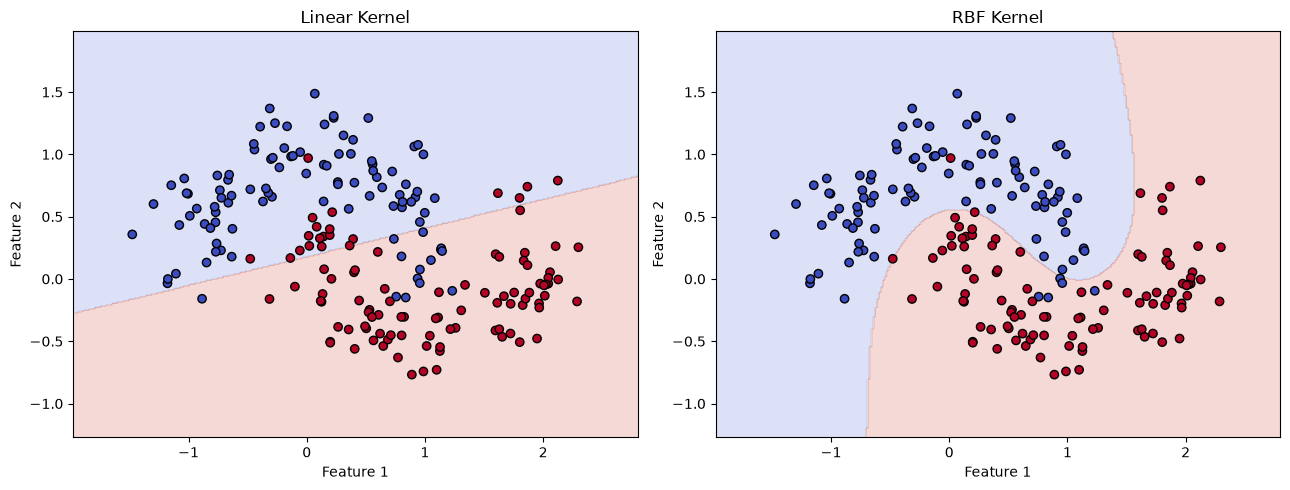

,Kernel,C,Training accuracy,Testing accuracy
0,Linear,1.0,0.8125,0.90
1,RBF,1.0,0.9625,0.95


In [7]:
X_moons, y_moons = make_moons(n_samples=200, noise=0.2, random_state=42)

X_moons_train, X_moons_test, y_moons_train, y_moons_test = train_test_split(
    X_moons, y_moons, test_size=0.20, random_state=42, stratify=y_moons
)

moon_models = {
    "Linear": SVC(kernel="linear"),
    "RBF": SVC(kernel="rbf")
}

moon_results = []

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

for ax, (kernel_name, model) in zip(axes, moon_models.items()):
    model.fit(X_moons_train, y_moons_train)
    train_accuracy = accuracy_score(y_moons_train, model.predict(X_moons_train))
    test_accuracy = accuracy_score(y_moons_test, model.predict(X_moons_test))

    moon_results.append({
        "Kernel": kernel_name,
        "C": model.C,
        "Training accuracy": train_accuracy,
        "Testing accuracy": test_accuracy
    })

    x_min, x_max = X_moons[:, 0].min() - 0.5, X_moons[:, 0].max() + 0.5
    y_min, y_max = X_moons[:, 1].min() - 0.5, X_moons[:, 1].max() + 0.5
    xx, yy = np.meshgrid(
        np.linspace(x_min, x_max, 300),
        np.linspace(y_min, y_max, 300)
    )
    predictions = model.predict(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)

    ax.contourf(xx, yy, predictions, alpha=0.2, cmap="coolwarm")
    ax.scatter(X_moons[:, 0], X_moons[:, 1], c=y_moons, cmap="coolwarm", edgecolors="k")
    ax.set_title(f"{kernel_name} Kernel")
    ax.set_xlabel("Feature 1")
    ax.set_ylabel("Feature 2")

plt.tight_layout()
plt.show()

moon_results_df = pd.DataFrame(moon_results)
display(moon_results_df)

**Question 6(c):** Which kernel works better on this dataset?

The RBF kernel generally works better than the linear kernel on the make_moons dataset because it can model nonlinear decision boundaries. The linear kernel uses a straight decision boundary, while the RBF kernel can create a curved boundary that follows the shape of the two classes. The actual accuracy comparison depends on the results obtained by running the models.

7. Implement a function that calculates each sample's hinge loss and the average hinge loss. Test it with `y = [1, -1, 1]` and scores `[0.5, 0.2, 1.5]`.

In [8]:
def average_hinge_loss(y_true, scores):
    y_true = np.asarray(y_true)
    scores = np.asarray(scores)
    losses = np.maximum(0, 1 - y_true * scores)
    return losses, losses.mean()

sample_y = [1, -1, 1]
sample_scores = [0.5, 0.2, 1.5]

sample_losses, average_loss = average_hinge_loss(sample_y, sample_scores)

for index, loss in enumerate(sample_losses, start=1):
    print(f"Sample {index} hinge loss:", loss)

print("Average hinge loss:", average_loss)

Sample 1 hinge loss: 0.5
Sample 2 hinge loss: 1.2
Sample 3 hinge loss: 0.0
Average hinge loss: 0.5666666666666667


8. Create a table comparing the trained models by kernel type, C value, training accuracy, and testing accuracy.

In [9]:
model_comparison = []

for C_value, model in C_models.items():
    model_comparison.append({
        "Kernel type": "linear",
        "C value": C_value,
        "Training accuracy": accuracy_score(y_train, model.predict(X_train)),
        "Testing accuracy": accuracy_score(y_test, model.predict(X_test))
    })

for kernel_name, model in moon_models.items():
    model_comparison.append({
        "Kernel type": kernel_name.lower(),
        "C value": model.C,
        "Training accuracy": accuracy_score(y_moons_train, model.predict(X_moons_train)),
        "Testing accuracy": accuracy_score(y_moons_test, model.predict(X_moons_test))
    })

model_comparison_df = pd.DataFrame(model_comparison)
display(model_comparison_df)

,Kernel type,C value,Training accuracy,Testing accuracy
0,linear,0.1,1.0000,1.00
1,linear,1.0,1.0000,1.00
2,linear,100.0,1.0000,1.00
3,linear,1.0,0.8125,0.90
4,rbf,1.0,0.9625,0.95


**Question 8(b):** Write 3–4 sentences explaining what you learned about margins, hinge loss, and kernels.

Margins are the distances between the decision boundary and the nearest data points, and a wider margin generally helps the SVM generalize better. Hinge loss measures classification errors and margin violations, becoming zero when \(yf(x) \geq 1\). The regularization parameter \(C\) controls the trade-off between maximizing the margin and minimizing classification errors. Linear kernels work well for linearly separable data, while RBF kernels can capture nonlinear patterns and often perform better on complex datasets.